# Forest proximity comparison with RotationForest

This tutorial compares proximity relations across a forest-family roster. The
default example uses OpenML's `optdigits` dataset (ID 28); the prior simulated
rotated-XOR workflow remains available through `DATA_SOURCE = "simulated"`.
Each relation is composed around an ordinary fitted estimator, which remains
available as `proximity.estimator`.

All examples use fixed seeds and a reduced smoke configuration by default.
`original`, `oob`, `kerf`, `path`, `englund`, `random_height`, and the
separately named isolation `collision` relation are symmetric affinities.
`rfgap`, `honest_gap`, and conditional weights are directed query-to-training
weights; downstream visualization, clustering, or attribution must state any
symmetrization. Prediction identity is claimed only for unsymmetrized `rfgap`
or `honest_gap` under their declared bootstrap/honesty contracts.

In [1]:
SMOKE = False
RANDOM_STATE = 0
N_SAMPLES = 80 if SMOKE else 800
N_ESTIMATORS = 20 if SMOKE else 300

# Default to OpenML optdigits (dataset ID 28). Set to "simulated" to restore
# the local rotated-XOR example below.
DATA_SOURCE = "openml"
OPENML_DATASET_ID = 28
SIMULATED_DATASET_NAME = "rotated_xor"
SIMULATED_DATASET_FEATURES = 2

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from forestgap import load_openml_dataset, load_simulated_dataset

if DATA_SOURCE == "openml":
    dataset = load_openml_dataset(dataset_id=OPENML_DATASET_ID, as_frame=False)
    dataset_source = f"OpenML dataset ID {dataset.dataset_id}"
elif DATA_SOURCE == "simulated":
    dataset = load_simulated_dataset(
        SIMULATED_DATASET_NAME,
        n_samples=N_SAMPLES,
        n_features=SIMULATED_DATASET_FEATURES,
        random_state=RANDOM_STATE,
    )
    dataset_source = "local simulation"
else:
    raise ValueError("DATA_SOURCE must be either 'openml' or 'simulated'.")

X = np.asarray(dataset.X, dtype=float)
y_raw = np.asarray(dataset.y)
if y_raw.ndim != 1:
    raise ValueError("This classification example requires a single target column.")
y = LabelEncoder().fit_transform(y_raw)

# Keep the default notebook execution tractable for dense precomputed Isomap.
# Simulations are already created at this size; OpenML data are stratified down.
if len(X) > N_SAMPLES:
    X, _, y, _ = train_test_split(
        X, y, train_size=N_SAMPLES, stratify=y, random_state=RANDOM_STATE,
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE,
)
{
    "dataset": dataset.name,
    "source": dataset_source,
    "description": dataset.description,
    "shape": X.shape,
    "class_counts": np.bincount(y).tolist(),
}

/yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode/forestgap/datasets.py:585: FutureWarning: Support for `dataset_format='array'` will be removed in 0.15,start using `dataset_format='dataframe' to ensure your code will continue to work. You can use the dataframe's `to_numpy` function to continue using numpy arrays.
  return dataset.get_data(target=target, dataset_format=dataset_format)


{'dataset': 'optdigits',
 'source': 'OpenML dataset ID 28',
 'description': '**Author**: E. Alpaydin, C. Kaynak  \n**Source**: [UCI](http://archive.ics.uci.edu/ml/datasets/optical+recognition+of+handwritten+digits)  \n**Please cite**: [UCI citation policy](https://archive.ics.uci.edu/ml/citation_policy.html)  \n\n1. Title of Database: Optical Recognition of Handwritten Digits\n \n 2. Source:\n  E. Alpaydin, C. Kaynak\n  Department of Computer Engineering\n  Bogazici University, 80815 Istanbul Turkey\n  alpaydin@boun.edu.tr\n  July 1998\n \n 3. Past Usage:\n  C. Kaynak (1995) Methods of Combining Multiple Classifiers and Their\n  Applications to Handwritten Digit Recognition, \n  MSc Thesis, Institute of Graduate Studies in Science and \n  Engineering, Bogazici University.\n \n  E. Alpaydin, C. Kaynak (1998) Cascading Classifiers, Kybernetika,\n  to appear. ftp://ftp.icsi.berkeley.edu/pub/ai/ethem/kyb.ps.Z\n \n 4. Relevant Information:\n  We used preprocessing programs made available by

In [3]:
import inspect

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    IsolationForest,
    RandomForestClassifier,
)

from forestgap import CanonicalCorrelationForestClassifier, Proximity, embed

try:
    from aeon.classification.sklearn import RotationForestClassifier
except ImportError:
    RotationForestClassifier = None

try:
    from treeple import (
        ExtendedIsolationForest,
        ExtraObliqueRandomForestClassifier,
        HonestForestClassifier,
        ObliqueRandomForestClassifier,
        PatchObliqueRandomForestClassifier,
        UnsupervisedObliqueRandomForest,
        UnsupervisedRandomForest,
    )
except ImportError:
    ExtendedIsolationForest = None
    ExtraObliqueRandomForestClassifier = None
    HonestForestClassifier = None
    ObliqueRandomForestClassifier = None
    PatchObliqueRandomForestClassifier = None
    UnsupervisedObliqueRandomForest = None
    UnsupervisedRandomForest = None

## RotationForest RF-GAP identity

`aeon` is optional. When installed, forestgap reconstructs aeon's per-tree
training-estimate roles for OOB/RF-GAP and uses the fitted rotation trees for
external-query weights. The checks below compare unsymmetrized RF-GAP weights
with the parent forest's test and OOB probabilities. OOB rows with no excluded
tree are reported rather than treated as an identity failure.

In [4]:
if RotationForestClassifier is None:
    rotation_forest = None
    rotation_result = {"status": "skipped", "reason": "install forestgap[aeon]"}
else:
    rotation_forest = RotationForestClassifier(
        n_estimators=max(8, N_ESTIMATORS), random_state=RANDOM_STATE, n_jobs=1,
    )
    rotation_rfgap = Proximity(rotation_forest, relation="rfgap").fit(X_train, y_train)
    test_weights = rotation_rfgap.prox_predict(X_test)
    test_error = float(np.max(np.abs(test_weights - rotation_forest.predict_proba(X_test))))

    oob_weights = rotation_rfgap.prox_predict()
    oob_valid = np.asarray(rotation_rfgap.oob_valid_mask_, dtype=bool)
    oob_reference = np.asarray(rotation_forest.oob_decision_function_)
    oob_error = (
        float(np.max(np.abs(oob_weights[oob_valid] - oob_reference[oob_valid])))
        if oob_valid.any()
        else None
    )
    assert test_error < 3e-5
    if oob_error is not None:
        assert oob_error < 3e-5

    rotation_result = {
        "status": "ok",
        "valid_relations": rotation_rfgap.capabilities_.valid_relations,
        "train_shape": rotation_rfgap.get_proximities().shape,
        "test_shape": rotation_rfgap.prox_extend(X_test).shape,
        "test_max_abs_error": test_error,
        "oob_max_abs_error": oob_error,
        "oob_valid_rows": int(oob_valid.sum()),
        "oob_invalid_rows": int((~oob_valid).sum()),
        "rfgap_diagnostics": rotation_rfgap.diagnostics(),
    }
rotation_result

{'status': 'ok',
 'valid_relations': ('englund',
  'kerf',
  'oob',
  'original',
  'path',
  'random_height',
  'rfgap'),
 'train_shape': (600, 600),
 'test_shape': (200, 600),
 'test_max_abs_error': 6.190190712240806e-07,
 'oob_max_abs_error': 2.8217399750118943e-08,
 'oob_valid_rows': 600,
 'oob_invalid_rows': 0,
 'rfgap_diagnostics': {'relation': 'rfgap',
  'shape': (600, 600),
  'directed': True,
  'symmetric': False,
  'psd': None,
  'min_eigenvalue': None,
  'nnz': 111423,
  'density': 0.30950833333333333,
  'value_min': 0.00010666667367331684,
  'value_max': 0.13951247930526733,
  'row_mass_min': 0.9999998211860657,
  'row_mass_max': 1.0000001192092896}}

## RotationForest path relations

Path and random-height relations are symmetric alternatives for geometry and
embedding. They intentionally use separate `Proximity` indexes around the
already fitted RotationForest; no parent forest is refit.

In [5]:
rotation_relation_rows = []
if rotation_forest is not None:
    for relation in ("original", "oob", "kerf", "path", "englund", "random_height"):
        relation_proximity = Proximity(
            rotation_forest, relation=relation, random_state=RANDOM_STATE,
        ).attach(X_train, y_train)
        train_relation = relation_proximity.get_proximities()
        diagnostics = relation_proximity.diagnostics(train_relation)
        rotation_relation_rows.append({
            "relation": relation,
            "train_shape": train_relation.shape,
            "test_shape": relation_proximity.prox_extend(X_test).shape,
            "symmetric": diagnostics["symmetric"],
            "psd": diagnostics["psd"],
        })
pd.DataFrame(rotation_relation_rows)

,relation,train_shape,test_shape,symmetric,psd
0,original,"(600, 600)","(200, 600)",True,None
1,oob,"(600, 600)","(200, 600)",True,None
2,kerf,"(600, 600)","(200, 600)",True,None
3,path,"(600, 600)","(200, 600)",True,None
4,englund,"(600, 600)","(200, 600)",True,None
5,random_height,"(600, 600)","(200, 600)",True,None


## Full symmetric multi-forest comparison

The roster includes RandomForest, ExtraTrees, CCF, RotationForest, Gradient
Boosting, IsolationForest, supervised and unsupervised oblique forests, and
Extended Isolation Forest. Optional families remain visible when their
dependency is unavailable. Gradient boosting is shown as capability-gated:
its additive trees do not define a valid forest proximity relation.

For every fitted forest, the comparison generates one Isomap embedding for each
symmetric relation its adapter exposes: `original`, `oob`, `kerf`, `path`,
`englund`, and `random_height`; isolation forests contribute `collision`.
RF-GAP is directed and is therefore excluded from Isomap.

In [6]:
def make_forest(estimator_class):
    parameters = inspect.signature(estimator_class.__init__).parameters
    kwargs = {"n_estimators": N_ESTIMATORS, "random_state": RANDOM_STATE}
    if "n_jobs" in parameters:
        kwargs["n_jobs"] = 1
    if "bootstrap" in parameters:
        kwargs["bootstrap"] = True
    return estimator_class(**kwargs)


# Symmetric core-adapter relations suitable for direct Isomap comparison.
ISOMAP_RELATIONS = (
    "original", "oob", "kerf", "path", "englund", "random_height", "collision",
)

family_specs = [
    ("RandomForest", lambda: RandomForestClassifier(
        n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE,
    ), "supervised", None),
    ("ExtraTrees", lambda: ExtraTreesClassifier(
        n_estimators=N_ESTIMATORS, bootstrap=True, random_state=RANDOM_STATE,
    ), "supervised", None),
    ("CanonicalCorrelationForest", lambda: CanonicalCorrelationForestClassifier(
        n_estimators=N_ESTIMATORS, bootstrap=True, random_state=RANDOM_STATE,
    ), "supervised", None),
    ("RotationForest", lambda: rotation_forest, "supervised", "install forestgap[aeon]"),
    ("GradientBoosting", lambda: GradientBoostingClassifier(
        n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE,
    ), "gated", "additive tree contributions are not a supported proximity relation"),
    ("IsolationForest", lambda: IsolationForest(
        n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE,
    ), "isolation", None),
    ("ObliqueRandomForest", lambda: make_forest(ObliqueRandomForestClassifier)
        if ObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("PatchObliqueRandomForest", lambda: make_forest(PatchObliqueRandomForestClassifier)
        if PatchObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("ExtraObliqueRandomForest", lambda: make_forest(ExtraObliqueRandomForestClassifier)
        if ExtraObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    # ("HonestForest", lambda: make_forest(HonestForestClassifier)
    #     if HonestForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("UnsupervisedRandomForest", lambda: make_forest(UnsupervisedRandomForest)
        if UnsupervisedRandomForest is not None else None, "unsupervised", "install forestgap[treeple]"),
    ("UnsupervisedObliqueRandomForest", lambda: make_forest(UnsupervisedObliqueRandomForest)
        if UnsupervisedObliqueRandomForest is not None else None, "unsupervised", "install forestgap[treeple]"),
    ("ExtendedIsolationForest", lambda: make_forest(ExtendedIsolationForest)
        if ExtendedIsolationForest is not None else None, "isolation", "install forestgap[treeple]"),
]


comparison_rows = []
embeddings = {}
for name, factory, family_type, unavailable_reason in family_specs:
    forest = factory()
    if forest is None:
        comparison_rows.append({
            "family": name,
            "status": "skipped",
            "reason": unavailable_reason,
            "relation": None,
            "parent_accuracy": None,
            "density": None,
        })
        continue

    if family_type == "gated":
        forest.fit(X_train, y_train)
        comparison_rows.append({
            "family": name,
            "status": "gated",
            "reason": unavailable_reason,
            "relation": None,
            "parent_accuracy": float((forest.predict(X_test) == y_test).mean()),
            "density": None,
        })
        continue

    initial_relation = "collision" if family_type == "isolation" else "original"
    indexed = Proximity(forest, relation=initial_relation)
    if family_type == "supervised":
        indexed.fit(X_train, y_train)
    else:
        indexed.fit(X_train)

    available_relations = [
        relation for relation in ISOMAP_RELATIONS
        if relation in indexed.capabilities_.valid_relations
    ]
    if not available_relations:
        comparison_rows.append({
            "family": name,
            "status": "skipped",
            "reason": "no symmetric proximity relation is available",
            "relation": None,
            "parent_accuracy": None,
            "density": None,
        })
        continue

    parent_accuracy = (
        float((forest.predict(X_test) == y_test).mean())
        if family_type == "supervised"
        else None
    )
    for relation in available_relations:
        proximity = indexed if relation == initial_relation else Proximity(
            forest, relation=relation, random_state=RANDOM_STATE,
        ).attach(X_train, y_train)
        coordinates = embed(proximity, method="isomap", n_components=2, n_neighbors=5)
        embeddings[(name, relation)] = coordinates
        comparison_rows.append({
            "family": name,
            "status": "ok",
            "reason": None,
            "relation": relation,
            "parent_accuracy": parent_accuracy,
            "density": proximity.diagnostics()["density"],
        })

comparison = pd.DataFrame(comparison_rows)
comparison

/yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode/.venv/lib/python3.11/site-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode/.venv/lib/python3.11/site-packages/scipy/sparse/_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
/yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode/.venv/lib/python3.11/site-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/yunity/rhodes8/ObliqueProximities/ObliqueProximi

,family,status,reason,relation,parent_accuracy,density
0,RandomForest,ok,None,original,0.945,0.452522
1,RandomForest,ok,None,oob,0.945,0.289678
2,RandomForest,ok,None,kerf,0.945,0.452522
3,RandomForest,ok,None,path,0.945,1.000000
4,RandomForest,ok,None,englund,0.945,1.000000
5,RandomForest,ok,None,random_height,0.945,1.000000
6,ExtraTrees,ok,None,original,0.955,0.391917
7,ExtraTrees,ok,None,oob,0.955,0.233633
8,ExtraTrees,ok,None,kerf,0.955,0.391917
9,ExtraTrees,ok,None,path,0.955,1.000000


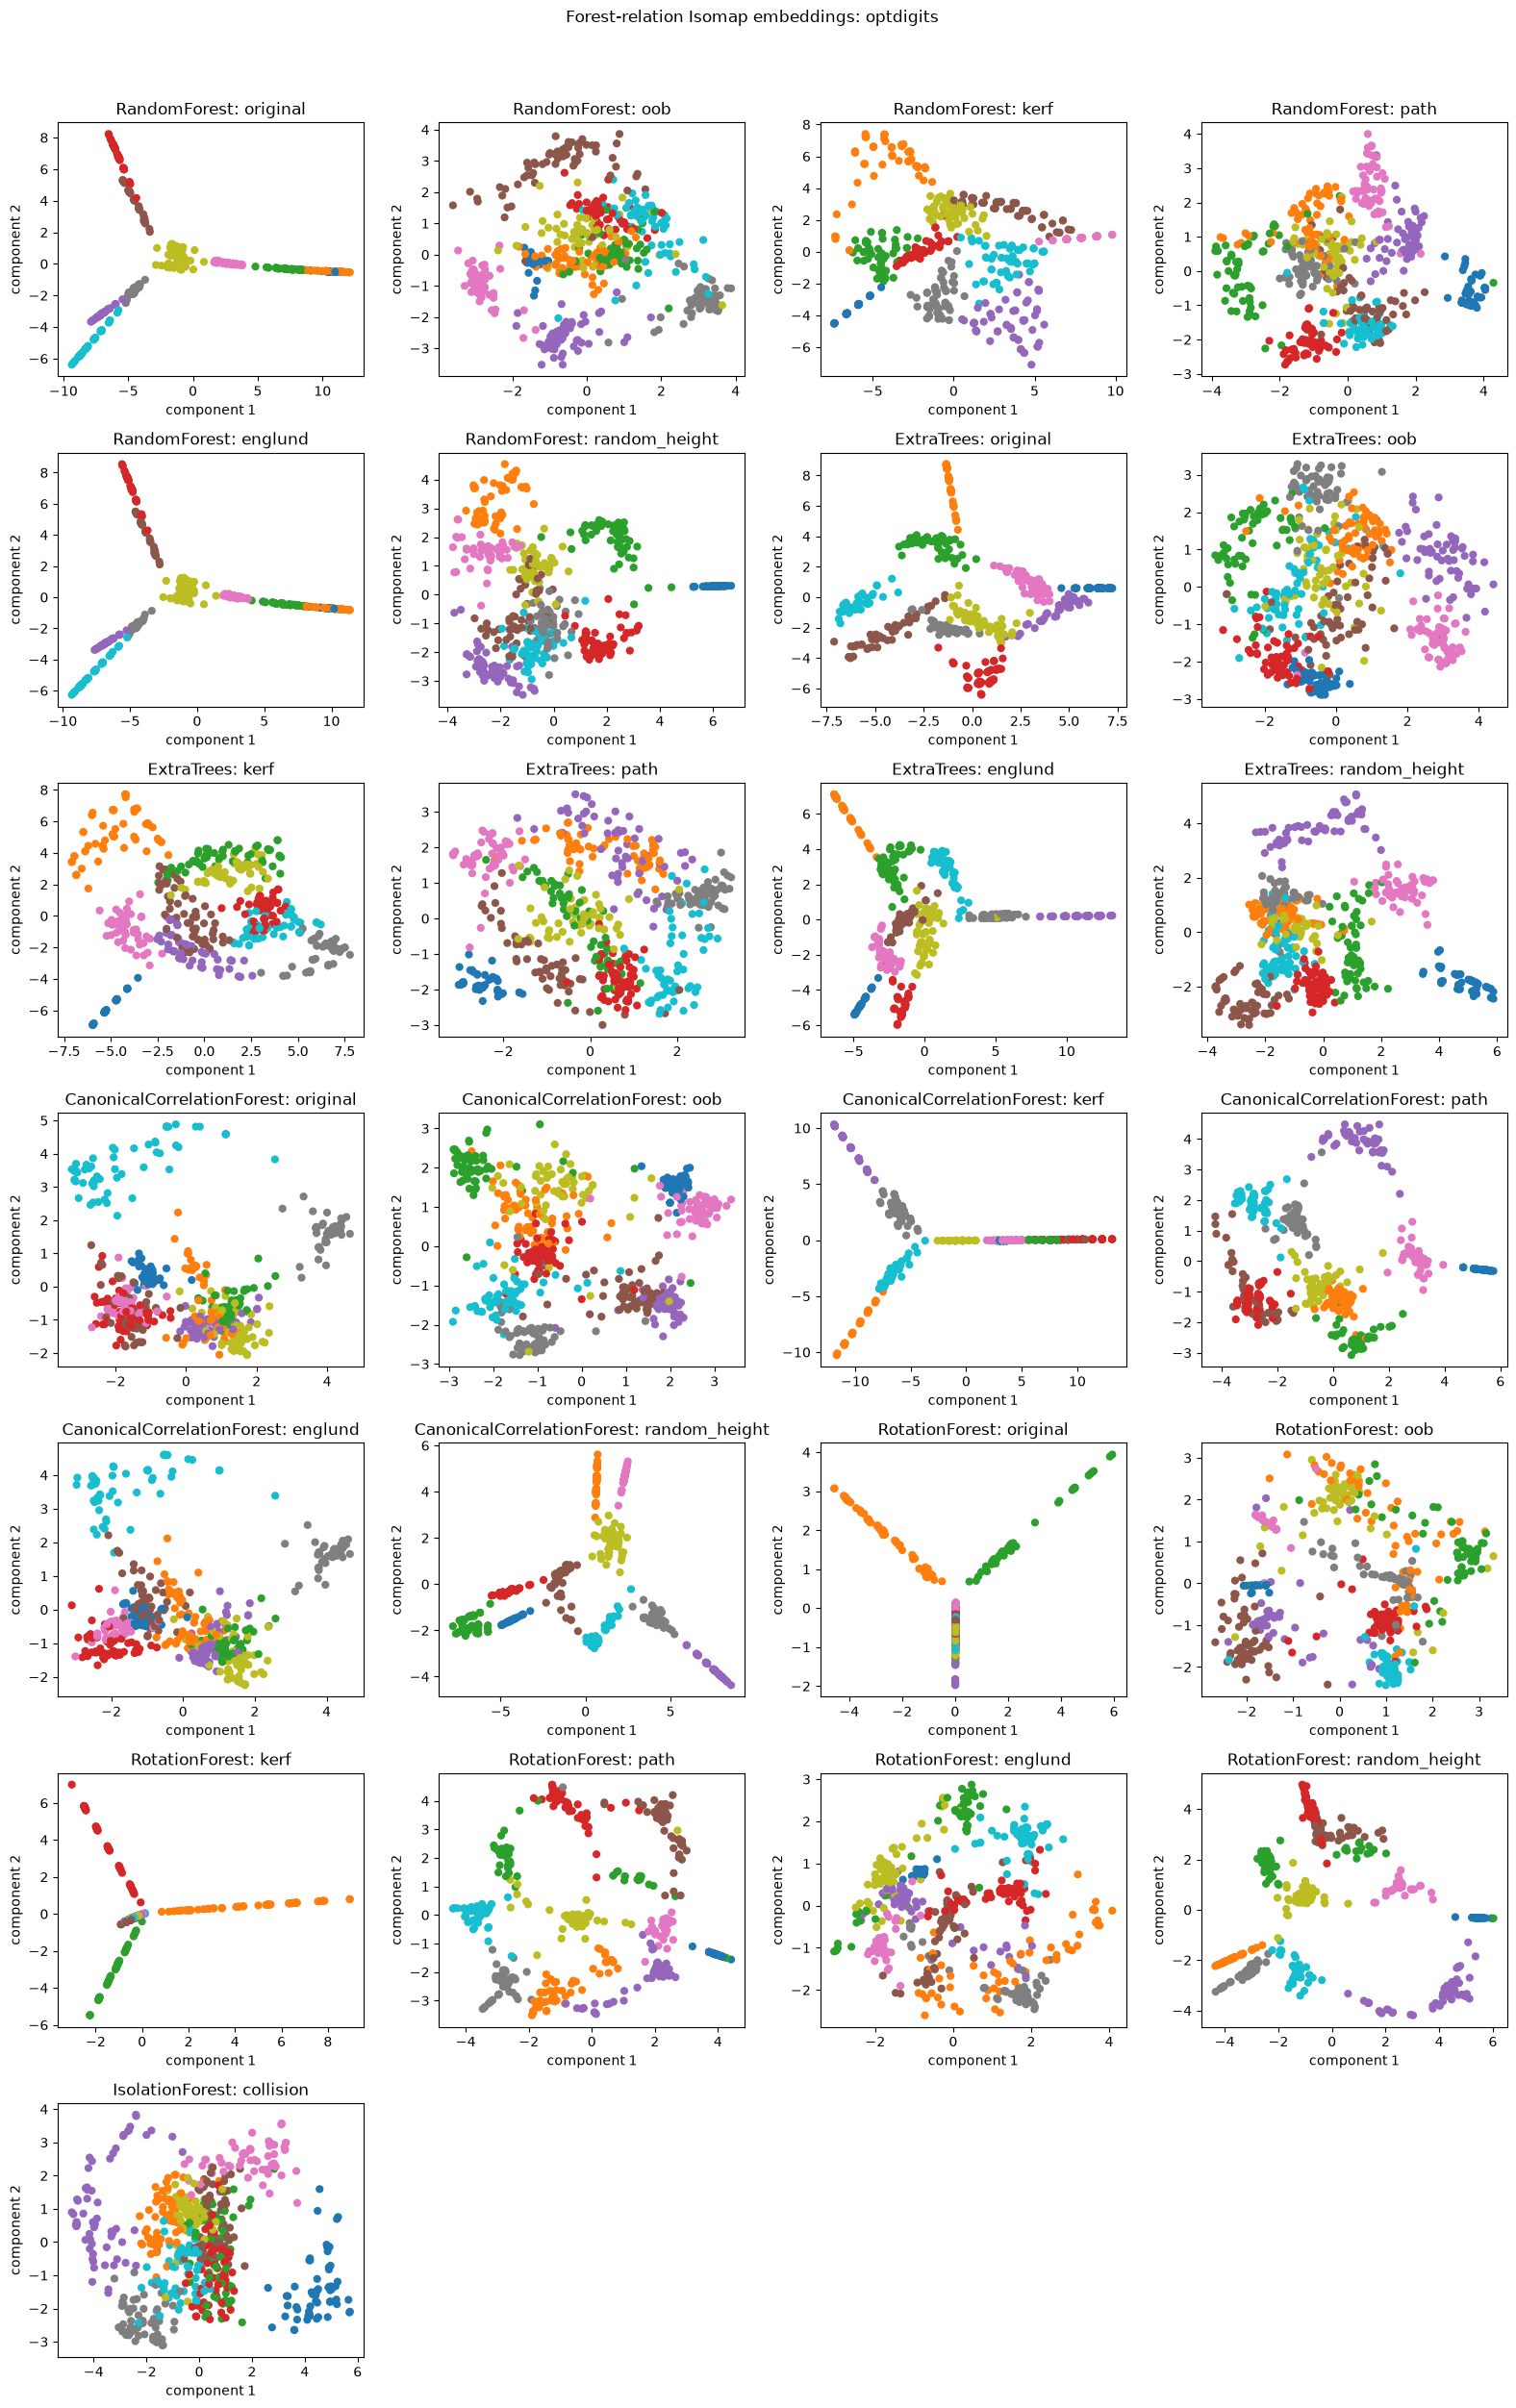

In [7]:
embedding_keys = list(embeddings)
n_embeddings = len(embedding_keys)
ncols = min(4, n_embeddings)
nrows = int(np.ceil(n_embeddings / ncols))
figure, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
for axis, (family, relation) in zip(axes.ravel(), embedding_keys):
    coordinates = embeddings[(family, relation)]
    axis.scatter(coordinates[:, 0], coordinates[:, 1], c=y_train, cmap="tab10", s=24)
    axis.set(title=f"{family}: {relation}", xlabel="component 1", ylabel="component 2")
for axis in axes.ravel()[n_embeddings:]:
    axis.axis("off")
figure.suptitle(f"Forest-relation Isomap embeddings: {dataset.name}", y=1.02)
figure.tight_layout()

## Reading the comparison

The default OpenML `optdigits` example makes differences in partition geometry
visible across handwritten-digit classes. Set `DATA_SOURCE = "simulated"` to
return to the local rotated-XOR example. Parent accuracy is reported only as
context; compare embeddings only among rows with the same declared symmetric
relation. Each model-relation pair receives its own Isomap panel, so
adapter-specific capability gaps remain explicit. Use the RF-GAP section
above—not these embeddings—when checking RotationForest prediction identity.